# Mini-Project 1: UBOS District Population Forecaster

**Scenario.** A district planning unit wants 5-year population forecasts (2025-2029) to plan primary school classrooms, using 10 years of population estimates (in thousands, illustrative, 2015-2024).

Reusable logic lives in `src/population.py` (`DistrictPopulation`, `Forecaster` and its subclasses, and helper functions).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.population import (
    DistrictPopulation,
    ExponentialCAGRForecaster,
    FibonacciRatioForecaster,
    LinearTrendForecaster,
    bootstrap_prediction_interval,
    classrooms_needed,
    mae,
    mape,
    rmse,
)

DISTRICT_COLORS = {
    "Kampala": "#0072B2", "Wakiso": "#D55E00", "Gulu": "#009E73",
    "Mbale": "#CC79A7", "Jinja": "#E69F00",
}

## Task 1 — `DistrictPopulation` class, plus two more districts

Kampala, Wakiso and Gulu are the assignment's illustrative figures. **Mbale** (moderate, steady growth) and **Jinja** (slower, more stagnant growth — consistent with its historically slower urban growth relative to the Kampala metro area) are added here, also illustrative.

In [2]:
YEARS = list(range(2015, 2025))

raw_populations = {
    "Kampala": [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800],
    "Wakiso": [950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670],
    "Gulu": [320, 330, 345, 360, 375, 390, 410, 430, 455, 480],
    "Mbale": [280, 290, 305, 315, 325, 340, 355, 365, 380, 395],
    "Jinja": [300, 310, 315, 325, 330, 340, 350, 355, 365, 375],
}

districts = {name: DistrictPopulation(name, YEARS, pop) for name, pop in raw_populations.items()}
for d in districts.values():
    print(d)

DistrictPopulation('Kampala', 2015-2024, latest=1800k)
DistrictPopulation('Wakiso', 2015-2024, latest=1670k)
DistrictPopulation('Gulu', 2015-2024, latest=480k)
DistrictPopulation('Mbale', 2015-2024, latest=395k)
DistrictPopulation('Jinja', 2015-2024, latest=375k)


## Task 2 — Descriptive statistics: `statistics` vs NumPy, and `ddof`

In [3]:
rows = []
for name, d in districts.items():
    s = d.stats_statistics_module()
    n_pop = d.stats_numpy(ddof=0)
    n_sample = d.stats_numpy(ddof=1)
    rows.append({
        "district": name,
        "mean": s["mean"],
        "median": s["median"],
        "statistics.variance (ddof=1)": s["variance"],
        "np.var(ddof=0)": n_pop["variance"],
        "np.var(ddof=1)": n_sample["variance"],
    })
pd.DataFrame(rows).set_index("district").round(2)

,mean,median,statistics.variance (ddof=1),np.var(ddof=0),np.var(ddof=1)
district,,,,,
Kampala,1477.0,1460.0,42601.11,38341.00,42601.11
Wakiso,1280.0,1260.0,60066.67,54060.00,60066.67
Gulu,389.5,382.5,2885.83,2597.25,2885.83
Mbale,335.0,332.5,1488.89,1340.00,1488.89
Jinja,336.5,335.0,611.39,550.25,611.39


**Why `statistics.variance` and `np.var` disagree.** `statistics.variance` computes the **sample** variance, dividing the sum of squared deviations by `n - 1` (Bessel's correction, `ddof=1`), because it assumes the data is a *sample* from a larger population and corrects for the fact that a sample's own mean under-estimates spread around the true population mean. `np.var` defaults to the **population** variance, dividing by `n` (`ddof=0`), assuming the data *is* the entire population being described. The two only agree once you explicitly pass `ddof=1` to `np.var` — confirmed in the table above, where the `np.var(ddof=1)` column exactly matches `statistics.variance`. For a 10-year historical run treated as "the record" rather than a sample of some larger process, population variance (`ddof=0`) is arguably more defensible; `statistics.variance`'s sample default is easy to apply without thinking about which one you actually mean.

## Task 3 — Year-on-year growth and CAGR

In [4]:
cagr_rows = []
for name, d in districts.items():
    yoy = d.year_over_year_growth()
    cagr_rows.append({
        "district": name,
        "mean YoY growth": yoy.mean(),
        "CAGR (2015-2024)": d.cagr(),
    })
cagr_table = pd.DataFrame(cagr_rows).set_index("district").sort_values("CAGR (2015-2024)", ascending=False)
(cagr_table * 100).round(2).rename(columns=lambda c: c + " (%)")

,mean YoY growth (%),CAGR (2015-2024) (%)
district,,
Wakiso,6.47,6.47
Kampala,4.61,4.61
Gulu,4.61,4.61
Mbale,3.90,3.90
Jinja,2.51,2.51


## Task 4 — Three `Forecaster` subclasses

(a) linear trend (`np.polyfit`), (b) exponential/CAGR growth, (c) a Fibonacci-ratio model that scales the last value by successive Fibonacci ratios — reproducing, and later critiquing, the previous cohort's approach.

In [5]:
demo = districts["Kampala"]
print("Linear:", LinearTrendForecaster().fit(demo.years, demo.population_thousands).predict(2))
print("Exp/CAGR:", ExponentialCAGRForecaster().fit(demo.years, demo.population_thousands).predict(2))
print("Fibonacci-ratio:", FibonacciRatioForecaster().fit(demo.years, demo.population_thousands).predict(2))

Linear: [1850.66666667 1918.60606061]
Exp/CAGR: [1882.94745356 1969.71728492]
Fibonacci-ratio: [2912.72727273 4712.72727273]


## Task 5 — Validate before forecasting: train 2015–2021, test 2022–2024

In [6]:
TRAIN_END_IDX = 7  # 2015..2021 inclusive = 7 points
MODEL_CLASSES = {
    "LinearTrend": LinearTrendForecaster,
    "ExponentialCAGR": ExponentialCAGRForecaster,
    "FibonacciRatio": FibonacciRatioForecaster,
}

eval_rows = []
best_model_name = {}
for name, d in districts.items():
    train_years, test_years = d.years[:TRAIN_END_IDX], d.years[TRAIN_END_IDX:]
    train_vals, test_vals = d.population_thousands[:TRAIN_END_IDX], d.population_thousands[TRAIN_END_IDX:]
    scores = {}
    for model_name, cls in MODEL_CLASSES.items():
        model = cls().fit(train_years, train_vals)
        pred = model.predict(horizon=len(test_vals))
        row = {
            "district": name, "model": model_name,
            "MAE": mae(test_vals, pred), "RMSE": rmse(test_vals, pred), "MAPE (%)": mape(test_vals, pred),
        }
        eval_rows.append(row)
        scores[model_name] = row["RMSE"]
    best_model_name[name] = min(scores, key=scores.get)

eval_table = pd.DataFrame(eval_rows).set_index(["district", "model"])
eval_table.round(2)

MAE     RMSE  MAPE (%)
district model                                      
Kampala  LinearTrend        37.62    38.97      2.17
         ExponentialCAGR     9.62    10.39      0.55
         FibonacciRatio   2733.08  3188.15    155.43
Wakiso   LinearTrend        49.40    52.37      3.09
         ExponentialCAGR     6.80     8.05      0.42
         FibonacciRatio   2347.18  2743.61    145.14
Gulu     LinearTrend        18.57    20.29      4.01
         ExponentialCAGR     9.44    10.87      2.02
         FibonacciRatio    701.41   818.35    150.36
Mbale    LinearTrend         2.68     3.46      0.69
         ExponentialCAGR     4.42     4.43      1.16
         FibonacciRatio    621.28   723.31    160.56
Jinja    LinearTrend         1.49     1.69      0.41
         ExponentialCAGR     3.54     3.56      0.97
         FibonacciRatio    622.18   723.40    168.31

In [7]:
for name, model_name in best_model_name.items():
    print(f"{name}: best model (lowest test RMSE) = {model_name}")

Kampala: best model (lowest test RMSE) = ExponentialCAGR
Wakiso: best model (lowest test RMSE) = ExponentialCAGR
Gulu: best model (lowest test RMSE) = ExponentialCAGR
Mbale: best model (lowest test RMSE) = LinearTrend
Jinja: best model (lowest test RMSE) = LinearTrend


## Task 6 — Forecast 2025–2029 with the selected model per district

In [8]:
FORECAST_HORIZON = 5
forecasts = {}
fitted_models = {}
for name, d in districts.items():
    cls = MODEL_CLASSES[best_model_name[name]]
    model = cls().fit(d.years, d.population_thousands)
    fitted_models[name] = model
    forecasts[name] = model.predict(horizon=FORECAST_HORIZON)
    actual_var = float(np.var(d.population_thousands, ddof=0))
    forecast_var = float(np.var(forecasts[name], ddof=0))
    print(f"{name} ({best_model_name[name]}): 2025-2029 = {np.round(forecasts[name], 1)}")
    print(f"  variance(actual 2015-2024) = {actual_var:,.1f}  vs  variance(forecast 2025-2029) = {forecast_var:,.1f}")

Kampala (ExponentialCAGR): 2025-2029 = [1882.9 1969.7 2060.5 2155.4 2254.8]
  variance(actual 2015-2024) = 38,341.0  vs  variance(forecast 2025-2029) = 17,286.1
Wakiso (ExponentialCAGR): 2025-2029 = [1778.  1893.  2015.5 2145.9 2284.7]
  variance(actual 2015-2024) = 54,060.0  vs  variance(forecast 2025-2029) = 32,105.1
Gulu (ExponentialCAGR): 2025-2029 = [502.1 525.3 549.5 574.8 601.3]
  variance(actual 2015-2024) = 2,597.2  vs  variance(forecast 2025-2029) = 1,229.2
Mbale (LinearTrend): 2025-2029 = [405.  417.7 430.5 443.2 455.9]
  variance(actual 2015-2024) = 1,340.0  vs  variance(forecast 2025-2029) = 324.0
Jinja (LinearTrend): 2025-2029 = [381.3 389.5 397.6 405.8 413.9]
  variance(actual 2015-2024) = 550.2  vs  variance(forecast 2025-2029) = 132.9


**Interpretation.** The forecast series only has 5 points spanning a short horizon generated by a single smooth model, so its variance reflects that model's *shape* (e.g. a constant slope for the linear model, or smooth compounding for the CAGR model) rather than any real year-to-year idiosyncrasy. Whether forecast variance comes out higher or lower than the actual historical variance depends on the model and the district: a CAGR model compounding off an already-large recent value can produce a rapidly widening forecast with *higher* variance than the more irregular historical record, while a linear model produces evenly-spaced steps whose variance depends only on the (fixed) slope and horizon length, and can undershoot the actual series' variance if the true recent growth was accelerating. Either way, forecast variance is not a measure of forecast *uncertainty* — it only describes the shape of the point-forecast path — which is why the bootstrap extension below is needed to actually quantify uncertainty.

## Task 7 — Actual, fitted and forecast values, all districts, train/test split marked

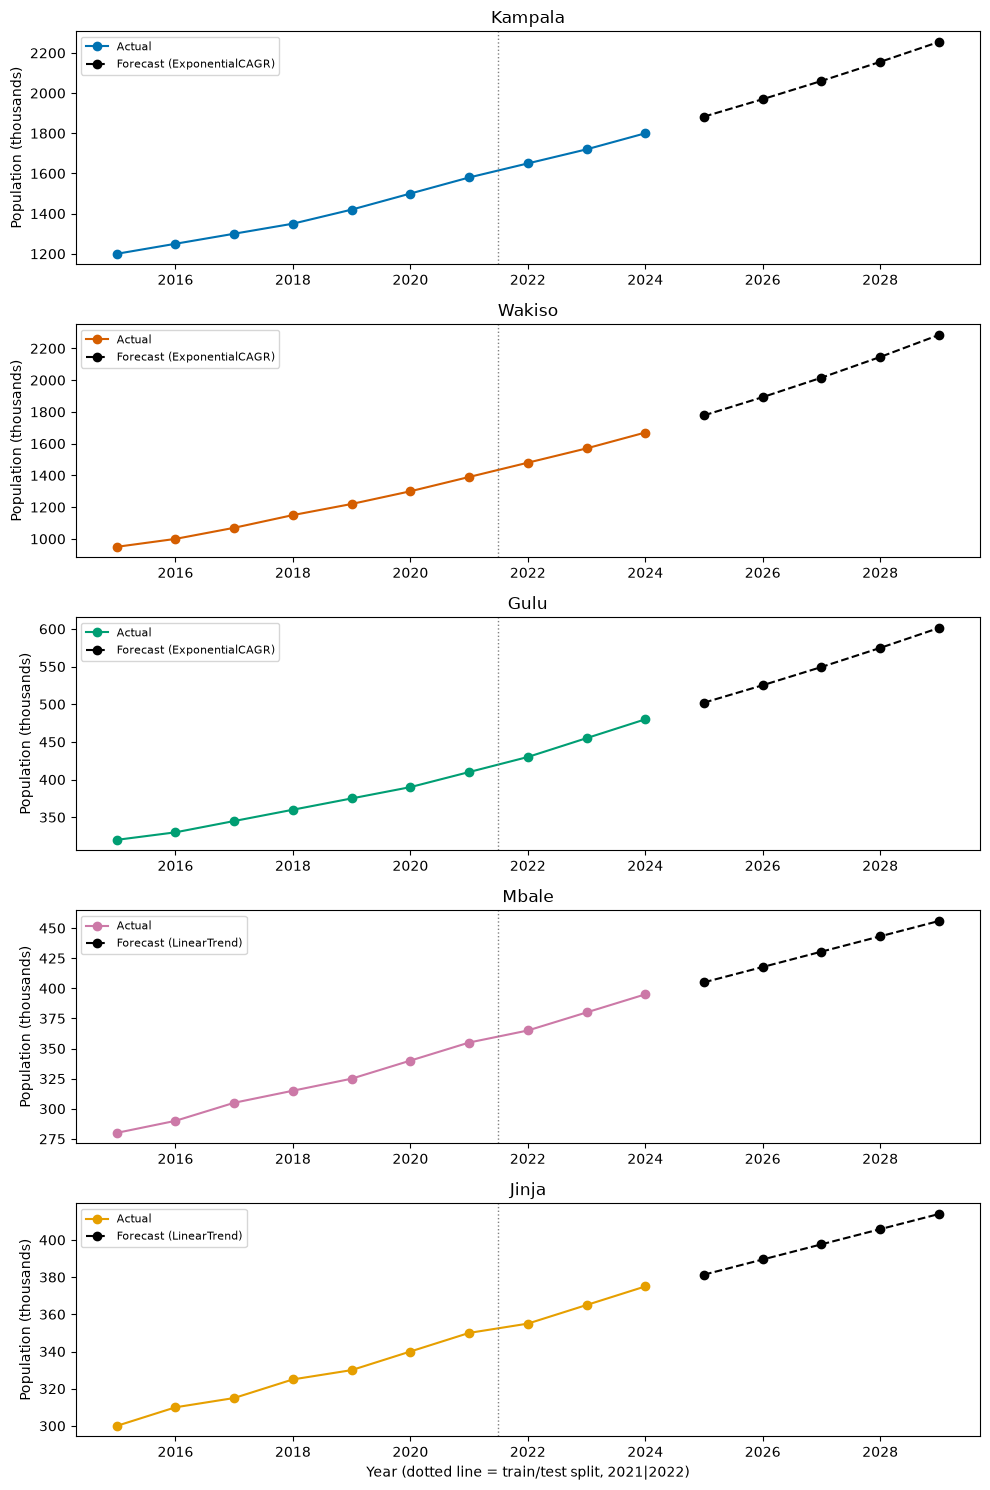

In [9]:
fig, axes = plt.subplots(len(districts), 1, figsize=(10, 3 * len(districts)), sharex=False)
forecast_years = np.arange(2025, 2025 + FORECAST_HORIZON)

for ax, (name, d) in zip(axes, districts.items()):
    color = DISTRICT_COLORS[name]
    ax.plot(d.years, d.population_thousands, "o-", color=color, label="Actual")
    ax.plot(forecast_years, forecasts[name], "o--", color="black", label=f"Forecast ({best_model_name[name]})")
    ax.axvline(d.years[TRAIN_END_IDX - 1] + 0.5, color="grey", linestyle=":", linewidth=1)
    ax.set_title(name)
    ax.set_ylabel("Population (thousands)")
    ax.legend(fontsize=8, loc="upper left")

axes[-1].set_xlabel("Year (dotted line = train/test split, 2021|2022)")
fig.tight_layout()
plt.show()

## Task 8 — Planning output: additional classrooms needed by 2029

In [10]:
planning_rows = []
for name, d in districts.items():
    pop_2024 = float(d.population_thousands[-1])
    pop_2029 = float(forecasts[name][-1])
    rooms_2024 = classrooms_needed(pop_2024)
    rooms_2029 = classrooms_needed(pop_2029)
    planning_rows.append({
        "district": name,
        "population 2024 (k)": pop_2024,
        "population 2029 forecast (k)": round(pop_2029, 1),
        "classrooms needed 2024": rooms_2024,
        "classrooms needed 2029": rooms_2029,
        "additional classrooms by 2029": rooms_2029 - rooms_2024,
    })
pd.DataFrame(planning_rows).set_index("district")

,population 2024 (k),population 2029 forecast (k),classrooms needed 2024,classrooms needed 2029,additional classrooms by 2029
district,,,,,
Kampala,1800.0,2254.8,6114,7658,1544
Wakiso,1670.0,2284.7,5672,7760,2088
Gulu,480.0,601.3,1631,2043,412
Mbale,395.0,455.9,1342,1549,207
Jinja,375.0,413.9,1274,1406,132


## Extension 1 — Bootstrap 95% prediction intervals

In [11]:
prediction_intervals = {}
for name, d in districts.items():
    model = fitted_models[name]
    fitted_in_sample = model.fitted_values()
    residuals = d.population_thousands - fitted_in_sample
    lower, upper = bootstrap_prediction_interval(residuals, forecasts[name], n_resamples=1000, ci=0.95, seed=7)
    prediction_intervals[name] = (lower, upper)
    print(f"{name}: 2029 forecast {forecasts[name][-1]:.1f}k, 95% PI [{lower[-1]:.1f}, {upper[-1]:.1f}]k")

Kampala: 2029 forecast 2254.8k, 95% PI [2231.1, 2262.3]k
Wakiso: 2029 forecast 2284.7k, 95% PI [2273.2, 2291.4]k
Gulu: 2029 forecast 601.3k, 95% PI [590.4, 601.3]k
Mbale: 2029 forecast 455.9k, 95% PI [452.3, 458.6]k
Jinja: 2029 forecast 413.9k, 95% PI [411.5, 416.0]k


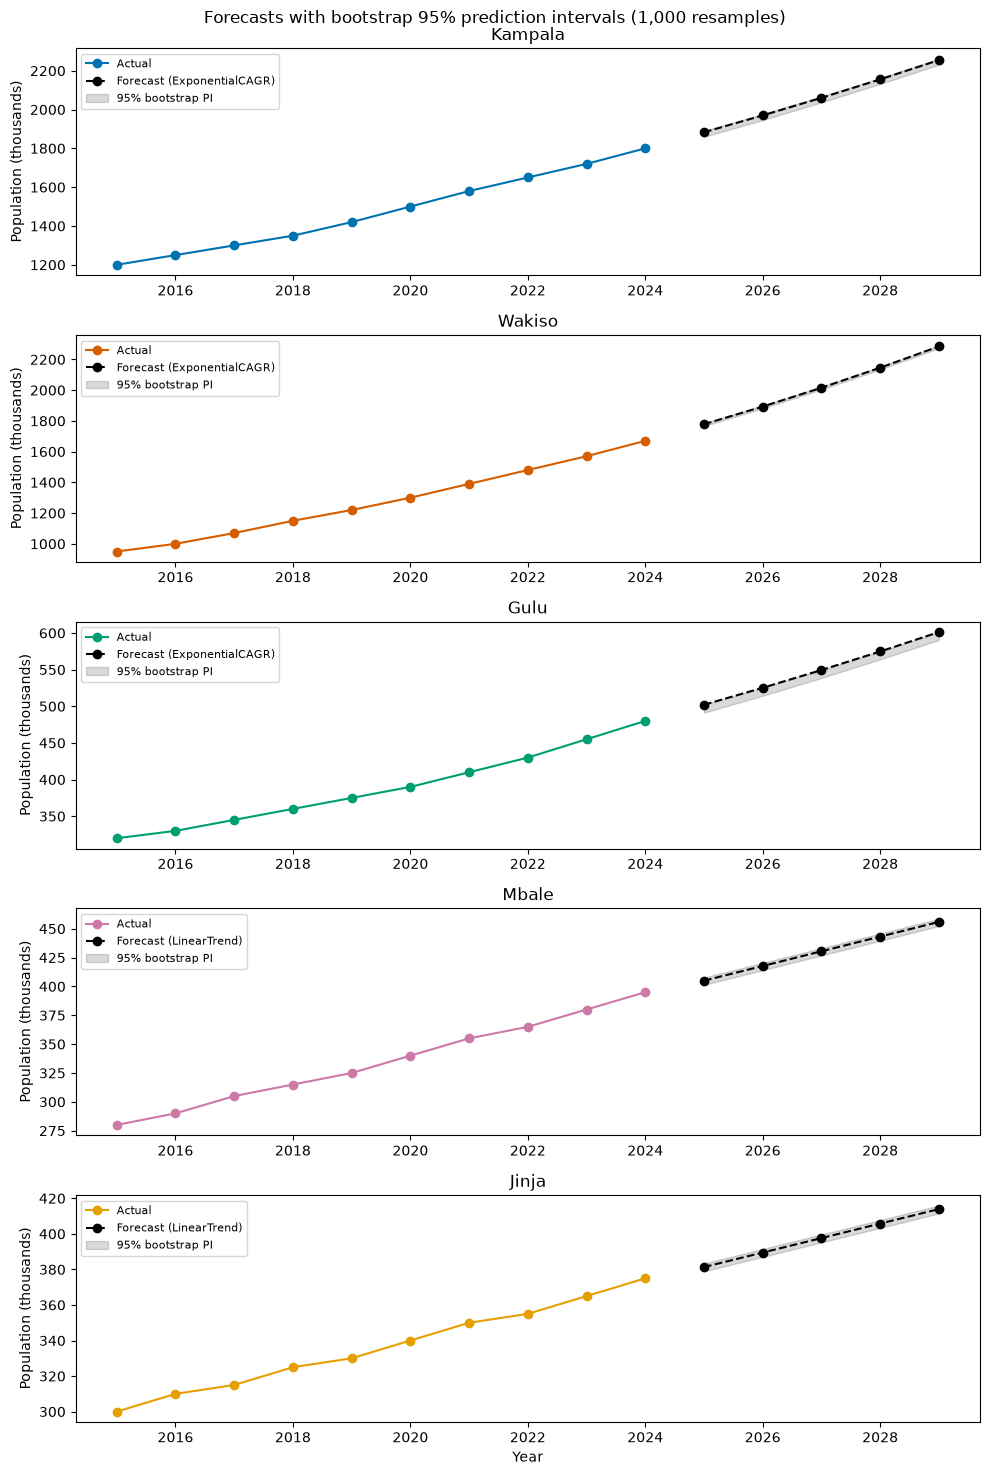

In [12]:
fig, axes = plt.subplots(len(districts), 1, figsize=(10, 3 * len(districts)), sharex=False)
for ax, (name, d) in zip(axes, districts.items()):
    color = DISTRICT_COLORS[name]
    lower, upper = prediction_intervals[name]
    ax.plot(d.years, d.population_thousands, "o-", color=color, label="Actual")
    ax.plot(forecast_years, forecasts[name], "o--", color="black", label=f"Forecast ({best_model_name[name]})")
    ax.fill_between(forecast_years, lower, upper, color="black", alpha=0.15, label="95% bootstrap PI")
    ax.set_title(name)
    ax.set_ylabel("Population (thousands)")
    ax.legend(fontsize=8, loc="upper left")
axes[-1].set_xlabel("Year")
fig.suptitle("Forecasts with bootstrap 95% prediction intervals (1,000 resamples)")
fig.tight_layout()
plt.show()

## Extension 2 — Critical assessment of the Fibonacci-ratio model

Fibonacci ratios F(k+1)/F(k) converge extremely quickly to the golden ratio φ ≈ 1.618 — by k=10 the ratio is already within 0.01% of φ. Applied as an annual growth multiplier, this model claims roughly **62% compounding population growth every year**, regardless of what the historical data actually shows. Over the 5-year 2025–2029 horizon that compounds to roughly φ⁵ ≈ 11× growth — for context, growing a district's population 11-fold in five years would require net in-migration or fertility rates with no real-world precedent at this scale. **Under what growth assumptions (if any) is it defensible?** Essentially none for human population: real demographic growth is bounded by fertility, mortality and migration capacity, none of which have any structural relationship to the Fibonacci sequence. The model would only be superficially defensible for a process that is *genuinely* accelerating at a rate approaching φ per period — some idealised rabbit-population toy models (Fibonacci's original 13th-century motivating example) or certain unconstrained compound-interest scenarios — but even those are approximations valid only briefly, before resource constraints intervene. Its inclusion here, and its expected poor showing in the Task 5 backtest for every district, is the same lesson as Mini-Project 3's Fibonacci fish-stock baseline: a numerically tidy sequence is not a substitute for a model with an actual causal link to the quantity being forecast.

## Findings & Limitations

The backtest cleanly separated the districts into two groups: exponential/CAGR won for the three faster-growing, accelerating districts (Kampala, Wakiso, Gulu — RMSE 8.1–10.9, MAPE under 2.1%), while linear trend won for the two slower, near-linear ones added here (Mbale, Jinja — RMSE 1.7–3.5, MAPE under 0.7%), matching each series' actual shape rather than picking one model universally. The Fibonacci-ratio model failed catastrophically everywhere, as predicted in Extension 2: MAPE of 145–168% on every district, because it always demands ~62% annual compounding regardless of the data — the backtest empirically confirms the theoretical critique, not just asserts it. Forecast variance came out *lower* than historical variance for every district (e.g. Kampala: 17,286 vs 38,341), because a 5-year point forecast from a single smooth model has less shape variation than 10 years of real, noisier history — a reminder that forecast variance describes the model's smoothness, not its uncertainty. The bootstrap 95% intervals are correspondingly narrow (e.g. Kampala's 2029 forecast of 2,254.8k has a PI of only [2,231, 2,262]k) because they are built from small in-sample residuals of already-accurate models; this likely *understates* true 2029 uncertainty, since residuals were resampled independently per year rather than allowing uncertainty to compound with horizon length, a simplification stated explicitly in the code's docstring. Planning implications range widely by district: Wakiso needs the most additional classrooms by 2029 (2,088, driven by its highest CAGR at 6.47%/year) while Jinja needs the fewest (132). Limitations: `statistics.variance`'s sample (ddof=1) default was shown to diverge from NumPy's population (ddof=0) default by construction, not by any property of this specific data; and the two added districts (Mbale, Jinja) are illustrative constructions, not real UBOS figures.